# Zak-OTFS (OTFS 2.0): the Zak lattice and a predictable channel

In `otfs_sim` OTFS was built as a precoder on top of OFDM: ISFFT → OFDM modulator. That is "OTFS 1.0". Its weak spot shows up in section 5 of that notebook: with **fractional** Doppler the pilot response is smeared by the Dirichlet kernel, the "integer paths" model is wrong, and BER hits a floor.

**Zak-OTFS** (Mohammed, Hadani, Chockalingam, Calderbank, 2022–2024) builds the same idea from first principles, through the **Zak transform**:
$$Z_x(\tau,\nu)=\sqrt{\tau_p}\sum_{k\in\mathbb Z}x(\tau+k\tau_p)\,e^{-j2\pi\nu k\tau_p},\qquad \tau_p\nu_p=1 .$$
This is a representation halfway between time and frequency: a function on the delay–Doppler plane that is **quasi-periodic** with period $\tau_p$ in delay and $\nu_p$ in Doppler:
$$Z(\tau+n\tau_p,\nu+m\nu_p)=e^{j2\pi n\nu\tau_p}\,Z(\tau,\nu).$$
The channel $r(t)=\sum_ih_ie^{j2\pi\nu_it}s(t-\tau_i)$ acts on it by a **twisted convolution**
$$Y(\tau,\nu)=\iint h(\tau',\nu')\,e^{j2\pi\nu'(\tau-\tau')}\,X(\tau-\tau',\nu-\nu')\,d\tau'd\nu' .$$
The "twist" phase appears because delay and Doppler do not commute: $T_\tau D_\nu=e^{-j2\pi\nu\tau}D_\nu T_\tau$.

The key property is **predictability**. If the channel "crystallizes", meaning its spread is smaller than the periods ($\tau_\max<\tau_p$, $2\nu_\max<\nu_p$), and the modulation pulse is well localized in DD, then the response to **one** pilot determines the response to **any** symbol, with no path model at all. That is what fixes fractional Doppler. The pulse matters here: a rectangular time window (as in OTFS 1.0) leaves Dirichlet tails $\propto1/\Delta\nu$, a Gaussian one leaves $e^{-\Delta\nu^2}$ tails.

The model in this notebook is simplified: integer delays, fractional Doppler, and a filter along the Doppler axis only (a time window). The frame is the same as in `otfs_sim` (64×16, $\nu_p=15$ kHz, 500 km/h), so the results compare directly.

1. Quasi-periodicity and the pulsone · 2. Non-commutativity and the twisted convolution · 3. Window = filter in DD: Dirichlet vs Gauss · 4. Predictability and crystallization · 5. Model-free channel estimation: BER · 6. Sensing: a target's Doppler from one pilot

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.special import erfc

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
M, N = 64, 16          # delay bins per period τp × Doppler bins per period νp
DF = 15e3              # νp = Δf, τp = 1/Δf: the same frame as in otfs_sim
FC_GHZ = 4.0
SPEED_KMH = 500
P_PATHS = 5            # delays 0…P−1 samples (integer), fractional Doppler
SIGMA = 0.25           # Gaussian time-window width as a fraction of the MN frame (the Doppler-axis filter)
L_CP = 8               # CP for the rectangular window (classic OTFS)
FRAMES = 20

rng = np.random.default_rng(SEED)

## Primitives: discrete Zak transform, windows, channel, twisted convolution, predicting H from a pilot

In [2]:
MN = M * N
FS = M * DF; T = N / DF                       # sample 1/B, frame T = N·τp
TAU_P, NU_P = 1 / DF, DF
NU_MAX = SPEED_KMH / 3.6 * FC_GHZ * 1e9 / 3e8
K_MAX = NU_MAX * T                            # Doppler in bins of 1/T
QPSK = np.array([1 + 1j, -1 + 1j, 1 - 1j, -1 - 1j]) / np.sqrt(2)
SPAN = (-MN // 2, 3 * MN // 2)                # absolute samples we model (the frame is [0, MN))
NABS = np.arange(*SPAN)

def crandn(shape, rng):
    return (rng.standard_normal(shape) + 1j * rng.standard_normal(shape)) / np.sqrt(2)

def qpsk_bits(B, n, rng):
    b = rng.integers(0, 2, (B, n, 2))
    return b, QPSK[b[..., 0] + 2 * b[..., 1]]

def hard_bits(z):
    return np.stack([z.real < 0, z.imag < 0], -1).astype(int)

# ---------- discrete Zak transform ----------
def idzt(X):
    """DD (…, M, N) → one period x[k + nM] = (1/√N) Σ_l X[k,l]·e^{j2πnl/N}, n = 0…N−1"""
    return (np.fft.ifft(X, axis=-1) * np.sqrt(N)).swapaxes(-1, -2).reshape(X.shape[:-2] + (MN,))

def dzt(y, n_abs=NABS):
    """Z[k,l] = (1/√N) Σ_{n ∈ ℤ} y[k + nM]·e^{−j2πnl/N} over every block of the signal (the infinite sum = folding the blocks modulo N)."""
    blocks = y.reshape(y.shape[:-1] + (-1, M))                       # block b starts at n_abs[0] + bM
    b0 = n_abs[0] // M
    fold = np.zeros(y.shape[:-1] + (N, M), complex)
    for b in range(blocks.shape[-2]):
        fold[..., (b0 + b) % N, :] += blocks[..., b, :]
    return (np.fft.fft(fold, axis=-2) / np.sqrt(N)).swapaxes(-1, -2)

def qp(Y, k, l):
    """value of a quasi-periodic function at any point (k, l): Y[k + nM, l] = e^{j2πnl/N}·Y[k, l], Y[k, l + N] = Y[k, l]"""
    n = np.floor_divide(k, M)
    return Y[..., k % M, l % N] * np.exp(2j * np.pi * n * l / N)

# ---------- windows: a Doppler-axis filter = a window in time ----------
def windows(kind, sigma=SIGMA):
    """'rect' — classic OTFS: transmit on [−CP, MN), receive on [0, MN). 'gauss' — Gaussian TX and RX windows with std σ·MN."""
    if kind == "rect":
        gt = ((NABS >= -L_CP) & (NABS < MN)).astype(float); gr = ((NABS >= 0) & (NABS < MN)).astype(float)
    else:
        gt = gr = np.exp(-(NABS - MN / 2)**2 / (2 * (sigma * MN)**2))
    return gt * np.sqrt(MN / np.sum(gt**2)), gr * np.sqrt(MN / np.sum(gr**2))

def tx(X, gt):
    """DD → periodic signal over the whole SPAN × TX window. Frame energy = MN·Es."""
    return idzt(X)[..., NABS % MN] * gt

def rx(r, gr):
    return dzt(r * gr)

def channel(s, paths):
    """r[n] = Σ h_i·e^{j2πν_i n/f_s}·s[n − l_i], n is absolute time (integer delays, any Doppler)"""
    r = np.zeros(s.shape, complex)
    for h, l, nu in paths:
        r[..., l:] += h * np.exp(2j * np.pi * nu * NABS[l:] / FS) * s[..., :s.shape[-1] - l]
    return r

def draw_paths(rng, integer=False, nu_max=None):
    nu_max = NU_MAX if nu_max is None else nu_max
    p = np.exp(-np.arange(P_PATHS) / 1.5); p /= p.sum()
    nu = nu_max * np.cos(rng.uniform(0, 2 * np.pi, P_PATHS))
    if integer:
        nu = np.round(nu * T) / T
    return [(np.sqrt(pi) * crandn((), rng), l, v) for l, (pi, v) in enumerate(zip(p, nu))]

EYE = np.eye(MN, dtype=complex).reshape(MN, M, N)

def eff_matrix(paths, kind, sigma=None):
    gt, gr = windows(kind, SIGMA if sigma is None else sigma)
    return rx(channel(tx(EYE, gt), paths), gr).reshape(MN, MN).T

def noise_whitener(kind):
    """after the RX window and the DZT the noise is correlated: C = R·Rᴴ; returns L⁻¹ (C = L·Lᴴ)"""
    _, gr = windows(kind)
    R = dzt(np.eye(len(NABS), dtype=complex) * gr).reshape(len(NABS), MN).T
    return np.linalg.inv(np.linalg.cholesky(R @ R.conj().T + 1e-9 * np.eye(MN)))

def lmmse(H, y, n0):
    return np.linalg.solve(H.conj().T @ H + n0 * np.eye(H.shape[1]), H.conj().T @ y.T).T

# ---------- twisted convolution and predicting the channel from a pilot ----------
def read_h(Yp, kp, lp, D, Q):
    """h[d, q] = Y_p[k_p + d, l_p + q]·e^{−j2πq(k_p + d)/MN} on the window d ∈ [D0, D1], q ∈ [−Q, Q]"""
    d = np.arange(D[0], D[1] + 1)[:, None]; q = np.arange(-Q, Q + 1)[None, :]
    return d, q, qp(Yp, kp + d, lp + q) * np.exp(-2j * np.pi * q * (kp + d) / MN)

def predict_H(d, q, h):
    """H[:, (k0,l0)]: y[k0+d, l0+q] = h[d,q]·e^{j2πq(k0+d)/MN}, then folded back to the fundamental domain by quasi-periodicity"""
    H = np.zeros((MN, MN), complex)
    k0, l0 = np.divmod(np.arange(MN), N)
    for (dd, qq), hv in np.ndenumerate(h):
        k = k0 + d[dd, 0]; l = l0 + q[0, qq]
        val = hv * np.exp(2j * np.pi * q[0, qq] * k / MN) * np.exp(-2j * np.pi * np.floor_divide(k, M) * l / N)
        np.add.at(H, ((k % M) * N + l % N, np.arange(MN)), val)
    return H

# self-checks
_, _x = qpsk_bits(2, MN, rng); _X = _x.reshape(2, M, N)
_y = dzt(idzt(_X)[..., NABS % MN] * ((NABS >= 0) & (NABS < MN)))
assert np.allclose(_y, _X), "DZT ∘ IDZT"
print(f"τp = {TAU_P*1e6:.1f} µs, νp = {NU_P/1e3:.0f} kHz, τp·νp = {TAU_P*NU_P:.0f}; grid {M}×{N}: Δτ = τp/M = {TAU_P/M*1e6:.2f} µs, Δν = νp/N = {NU_P/N:.1f} Hz")
print(f"{SPEED_KMH} km/h at {FC_GHZ} GHz: ν_max = {NU_MAX:.0f} Hz = {K_MAX:.2f} bins; crystallization: τ_max = {P_PATHS-1} ≪ M = {M}, 2ν_max = {2*K_MAX:.1f} < N = {N} bins")

τp = 66.7 µs, νp = 15 kHz, τp·νp = 1; grid 64×16: Δτ = τp/M = 1.04 µs, Δν = νp/N = 937.5 Hz
500 km/h at 4.0 GHz: ν_max = 1852 Hz = 1.98 bins; crystallization: τ_max = 4 ≪ M = 64, 2ν_max = 4.0 < N = 16 bins


## 1. Quasi-periodicity and the pulsone
The discrete version: $Z[k,l]=\frac1{\sqrt N}\sum_{n\in\mathbb Z}y[k+nM]\,e^{-j2\pi nl/N}$, with $k$ the delay in samples of $1/B$ and $l$ the Doppler in bins of $1/T$. The sum runs over **every** block of the signal, not over a single frame. Quasi-periodicity $Z[k+M,l]=e^{j2\pi l/N}Z[k,l]$ checks out to machine precision.

A symbol at $(k_0,l_0)$ is a **pulsone**: in time, pulses every $\tau_p$ whose phase rotates at $l_0\nu_p/N$; in frequency, a comb every $\nu_p$, offset by $l_0\nu_p/N$. It is localized neither in time nor in frequency, but it is localized on the DD lattice. A time window is a filter along the Doppler axis:
- **rectangular** (OTFS 1.0): exactly $N$ pulses, and without a channel the symbols are orthogonal;
- **Gaussian**: a bell-shaped pulse envelope. Even without a channel it couples neighbouring Doppler bins (right: 0.54 at ±1), i.e. the symbols are not orthogonal. Localization is paid for with non-orthogonality, which shows up again in section 5.

Quasi-periodicity: max|Z[k+M,l] − e^(j2πl/N)·Z[k,l]| = 3.4e-16, max|Z[k,l+N] − Z[k,l]| = 2.0e-15


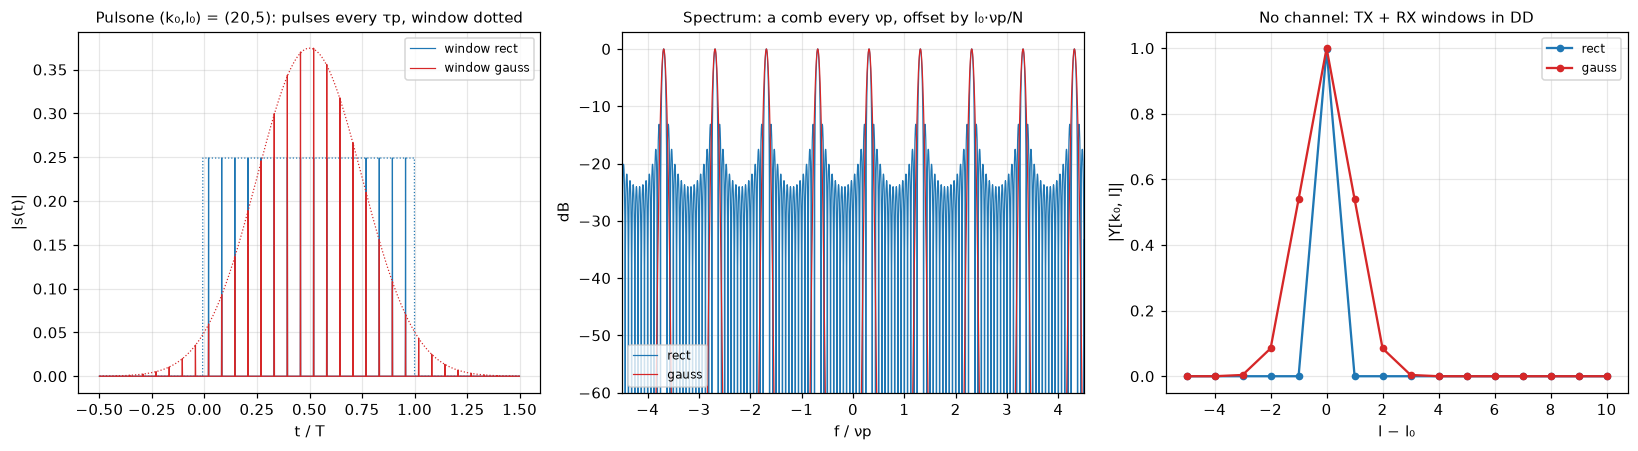

Gaussian window σ = 0.25·T: 99 % of the energy within 0.91·T — no longer than the frame, but its edges are nearly empty and the middle carries more
Without a channel the Gaussian windows themselves couple neighbouring Doppler bins: |Y[k₀, l₀±1]| = 0.540, |Y[k₀, l₀±2]| = 0.085


In [3]:
# (a) quasi-periodicity
x = idzt(_X[0])
Xbig = dzt(x[NABS % MN] * ((NABS >= 0) & (NABS < MN)))
k, l = np.meshgrid(np.arange(-M, 2 * M), np.arange(-N, 2 * N), indexing="ij")
print(f"Quasi-periodicity: max|Z[k+M,l] − e^(j2πl/N)·Z[k,l]| = {np.max(np.abs(qp(Xbig, k + M, l) - np.exp(2j*np.pi*l/N) * qp(Xbig, k, l))):.1e}, "
      f"max|Z[k,l+N] − Z[k,l]| = {np.max(np.abs(qp(Xbig, k, l + N) - qp(Xbig, k, l))):.1e}")

# (b) the pulsone: one DD symbol in time and in frequency
k0, l0 = 20, 5
P = np.zeros((M, N), complex); P[k0, l0] = 1
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, kind, c in ((ax[0], "rect", "C0"), (ax[0], "gauss", "C3")):
    gt, _ = windows(kind)
    s = tx(P, gt)
    a.plot(NABS / MN, np.abs(s), c, lw=0.8, label=f"window {kind}")
    a.plot(NABS / MN, gt / gt.max() * np.abs(s).max(), c + ":", lw=0.8)
ax[0].set_xlabel("t / T"); ax[0].set_ylabel("|s(t)|"); ax[0].legend(fontsize=8)
ax[0].set_title(f"Pulsone (k₀,l₀) = ({k0},{l0}): pulses every τp, window dotted", fontsize=10)
for kind, c in (("rect", "C0"), ("gauss", "C3")):
    gt, _ = windows(kind)
    S = np.fft.fftshift(np.fft.fft(tx(P, gt), 8 * len(NABS))); f = np.fft.fftshift(np.fft.fftfreq(8 * len(NABS), 1 / FS))
    ax[1].plot(f / DF, 20 * np.log10(np.abs(S) / np.abs(S).max() + 1e-9), c, lw=0.8, label=kind)
ax[1].set_xlim(-4.5, 4.5); ax[1].set_ylim(-60, 3); ax[1].set_xlabel("f / νp"); ax[1].set_ylabel("dB"); ax[1].legend(fontsize=8)
ax[1].set_title("Spectrum: a comb every νp, offset by l₀·νp/N", fontsize=10)
for kind, c in (("rect", "C0"), ("gauss", "C3")):
    gt, gr = windows(kind)
    Y = rx(tx(P, gt), gr)
    ax[2].plot(np.arange(N) - l0, np.abs(Y[k0]), c + "o-", ms=4, label=kind)
ax[2].set_xlabel("l − l₀"); ax[2].set_ylabel("|Y[k₀, l]|"); ax[2].legend(fontsize=8)
ax[2].set_title("No channel: TX + RX windows in DD", fontsize=10)
plt.tight_layout(); plt.show()
gt, gr = windows("gauss")
e = np.cumsum(np.sort(gt**2)[::-1]) / np.sum(gt**2)
print(f"Gaussian window σ = {SIGMA}·T: 99 % of the energy within {np.argmax(e > 0.99)/MN:.2f}·T — no longer than the frame, but its edges are nearly empty and the middle carries more")
Y = rx(tx(P, gt), gr)
print(f"Without a channel the Gaussian windows themselves couple neighbouring Doppler bins: |Y[k₀, l₀±1]| = {abs(Y[k0, l0+1]):.3f}, |Y[k₀, l₀±2]| = {abs(Y[k0, l0+2]):.3f}")

## 2. Non-commutativity and the twisted convolution
A shift by $d$ samples and a Doppler of $q$ bins applied in different orders give signals that differ by a factor $e^{-j2\pi qd/MN}$: that is the check in the first output line. Hence the discrete input–output for a path $(h,d,q)$ with integer $d,q$:
$$y[k,l]=h\,e^{\,j2\pi qk/MN}\,x[k-d,\,l-q],$$
with $x$ extended quasi-periodically. This matches the time-domain simulation **exactly**. A plain 2-D convolution without the phase is off by 36 %.

The figure shows the responses to pilots at two places in the frame. The magnitudes are the same, but the phases differ, and the twist predicts them. In OTFS 1.0 these phases $\phi_i(l,k)$ had to be derived for the specific modem. Here they are a property of the DD plane.

T_τ D_ν = e^(−j2πντ)·D_ν T_τ: ratio = (0.9993-0.0368j), theory e^(−j2π q d/MN) = (0.9993-0.0368j) (the same for every n: spread 3.7e-15)


Twisted convolution y[k,l] = Σ h_i·e^(j2π q_i k/MN)·x[k − d_i, l − q_i] vs time-domain simulation: max|Δ| = 2.4e-15
Without the twist (a plain 2-D convolution): relative error 0.36 — the phase e^(j2πqk/MN) is not negligible


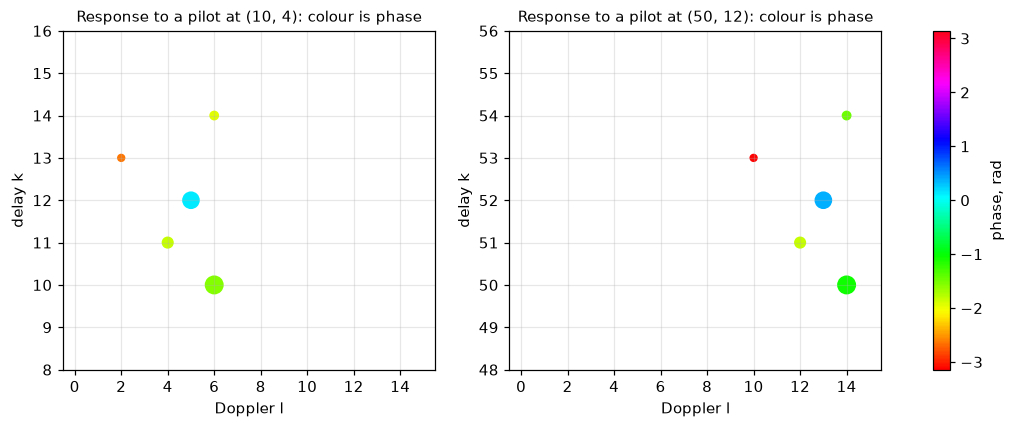

In [4]:
# delay and Doppler shifts do not commute
s = crandn(len(NABS), rng); d, q = 3, 2.0
Tz = lambda v: np.r_[np.zeros(d), v[:-d]]
Dz = lambda v: v * np.exp(2j * np.pi * q * NABS / MN)
ratio = Tz(Dz(s))[d:] / Dz(Tz(s))[d:]
print(f"T_τ D_ν = e^(−j2πντ)·D_ν T_τ: ratio = {np.round(ratio[0], 4)}, theory e^(−j2π q d/MN) = {np.round(np.exp(-2j*np.pi*q*d/MN), 4)} (the same for every n: spread {np.ptp(np.abs(ratio - ratio[0])):.1e})")

# input–output: twisted convolution vs time-domain simulation
pth = draw_paths(np.random.default_rng(3), integer=True)
H = eff_matrix(pth, "rect")
_, xd = qpsk_bits(1, MN, rng); X = xd[0].reshape(M, N)
y_time = (H @ xd[0]).reshape(M, N) / (windows("rect")[0].max() * windows("rect")[1].max())   # undo the windows' energy normalization
kk, ll = np.meshgrid(np.arange(M), np.arange(N), indexing="ij")
y_tw = sum(h * np.exp(2j * np.pi * (nu * T) * kk / MN) * qp(X, kk - l, ll - int(round(nu * T))) for h, l, nu in pth)
print(f"Twisted convolution y[k,l] = Σ h_i·e^(j2π q_i k/MN)·x[k − d_i, l − q_i] vs time-domain simulation: max|Δ| = {np.max(np.abs(y_tw - y_time)):.1e}")
y_naive = sum(h * qp(X, kk - l, ll - int(round(nu * T))) for h, l, nu in pth)
print(f"Without the twist (a plain 2-D convolution): relative error {np.linalg.norm(y_naive - y_time)/np.linalg.norm(y_time):.2f} — the phase e^(j2πqk/MN) is not negligible")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (kp, lp) in zip(ax, ((10, 4), (50, 12))):
    Pp = np.zeros((M, N), complex); Pp[kp, lp] = 1
    Yp = (H @ Pp.ravel()).reshape(M, N)
    m = np.abs(Yp) > 1e-6
    ki, li = np.nonzero(m)
    sc = a.scatter(li, ki, c=np.angle(Yp[m]), s=120 * np.abs(Yp[m]) / np.abs(Yp).max() + 10, cmap="hsv", vmin=-np.pi, vmax=np.pi)
    a.set_xlim(-0.5, N - 0.5); a.set_ylim(kp - 2, kp + P_PATHS + 1)
    a.set_xlabel("Doppler l"); a.set_ylabel("delay k"); a.set_title(f"Response to a pilot at ({kp}, {lp}): colour is phase", fontsize=10)
plt.colorbar(sc, ax=ax, label="phase, rad"); plt.show()

## 3. Window = filter in DD: Dirichlet vs Gauss
One path with a Doppler exactly halfway between bins (3.5 bins). The DD response is the spectrum of the TX·RX window product, shifted by $\nu$:
- **rectangle** of length $T$ → $\big|\frac{\sin\pi\Delta\nu T}{N\sin(\pi\Delta\nu T/N)}\big|$: the tails decay as $1/\Delta\nu$, and 9 % of the energy stays outside the 4 nearest bins;
- **Gaussian** with std $\sigma$ (the product has $\sigma/\sqrt2$) → $\exp\!\big(-2\pi^2(\sigma/\sqrt2)^2\Delta\nu^2\big)$: 0.06 % outside 4 bins.

The simulated points fall on both formulas.

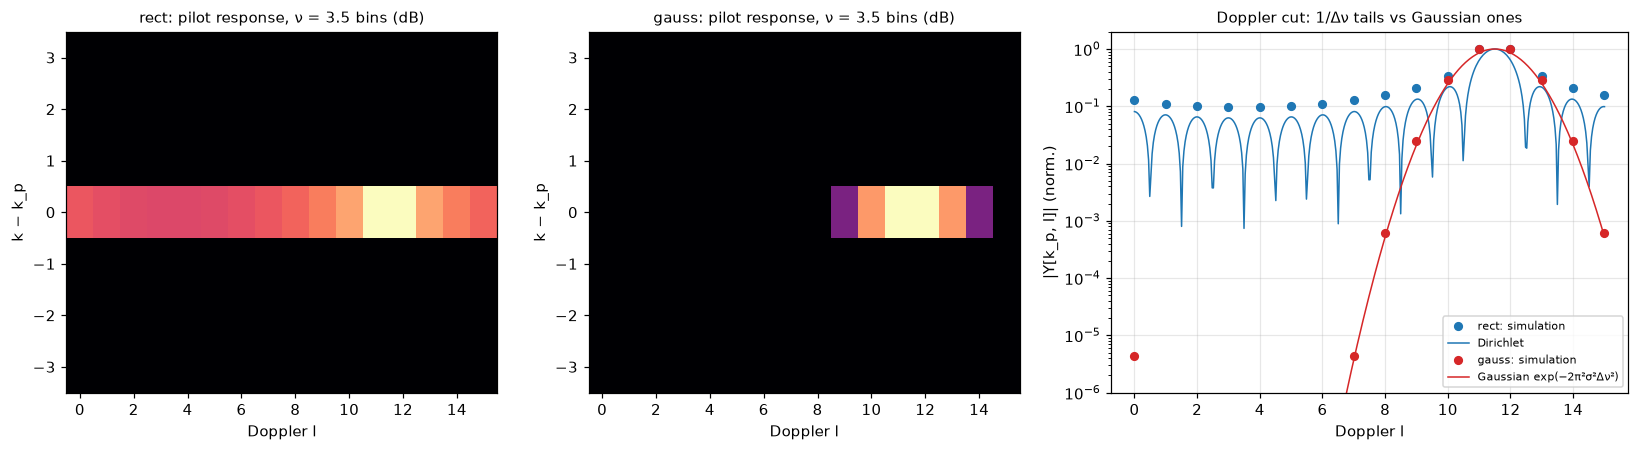

rect : energy outside the 2 / 4 nearest bins 18.7% / 9.41%
gauss: energy outside the 2 / 4 nearest bins 7.9% / 0.06%


In [5]:
from scipy.special import erf
def dirichlet(x):
    with np.errstate(invalid="ignore", divide="ignore"):
        v = np.abs(np.sin(np.pi * x) / (N * np.sin(np.pi * x / N)))
    return np.where(np.abs(np.sin(np.pi * x / N)) < 1e-12, 1.0, v)

one = [(1.0, 0, 3.5 / T)]                                     # one path, Doppler exactly halfway between bins
kp, lp = M // 2, N // 2
Pp = np.zeros((M, N), complex); Pp[kp, lp] = 1
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1, 1.2]})
cuts = {}
for a, kind in zip(ax[:2], ("rect", "gauss")):
    gt, gr = windows(kind)
    Y = rx(channel(tx(Pp, gt), one), gr)
    cuts[kind] = np.abs(Y[kp]) / np.abs(Y).max()
    a.imshow(20 * np.log10(np.abs(Y[kp - 3:kp + 4]) / np.abs(Y).max() + 1e-9), origin="lower", aspect="auto", cmap="magma",
             vmin=-50, vmax=0, extent=[-0.5, N - 0.5, -3.5, 3.5])
    a.set_xlabel("Doppler l"); a.set_ylabel("k − k_p"); a.grid(False)
    a.set_title(f"{kind}: pilot response, ν = {3.5} bins (dB)", fontsize=10)
lg = np.linspace(0, N - 1, 400)
ax[2].semilogy(np.arange(N), cuts["rect"], "C0o", ms=5, label="rect: simulation")
ax[2].semilogy(lg, dirichlet(lg - lp - 3.5), "C0-", lw=1, label="Dirichlet")
sg = SIGMA * MN / np.sqrt(2)                                   # std of the TX·RX window product
theory = np.exp(-2 * (np.pi * sg * (lg - lp - 3.5) / MN)**2)
ax[2].semilogy(np.arange(N), cuts["gauss"], "C3o", ms=5, label="gauss: simulation")
ax[2].semilogy(lg, theory, "C3-", lw=1, label="Gaussian exp(−2π²σ²Δν²)")
ax[2].set_ylim(1e-6, 2); ax[2].set_xlabel("Doppler l"); ax[2].set_ylabel("|Y[k_p, l]| (norm.)"); ax[2].legend(fontsize=7)
ax[2].set_title("Doppler cut: 1/Δν tails vs Gaussian ones", fontsize=10)
plt.tight_layout(); plt.show()
for kind in cuts:
    c2 = cuts[kind]**2 / np.sum(cuts[kind]**2); near = np.sort(c2)[::-1]
    print(f"{kind:5}: energy outside the 2 / 4 nearest bins {1 - near[:2].sum():.1%} / {1 - near[:4].sum():.2%}")

## 4. Predictability and crystallization
A noise-free experiment. Take the response to one pilot, read $h[d,q]$ from a window around the pilot (across the whole Doppler axis), build the **entire** $H_\text{eff}$ matrix ($MN\times MN$) by twisted convolution, and compare it with the real one:
$$h[d,q]=Y_p[k_p+d,\,l_p+q]\,e^{-j2\pi q(k_p+d)/MN},\qquad \hat y_{k_0,l_0}[k_0+d,l_0+q]=h[d,q]\,e^{j2\pi q(k_0+d)/MN}.$$
- **Rectangular window, integer Doppler** — exact, to machine precision.
- **Rectangular window, fractional Doppler** — NMSE ≈ −20 dB. The response to a symbol near the frame edge is cut by the window differently from the pilot's response. This is the same floor as in `otfs_sim`.
- **Gaussian window** — down to −150 dB: the signal itself fades towards the edges, there is nothing to cut, and the system becomes invariant to twisted shifts. A window that is too narrow ($\sigma=0.12T$) spreads in Doppler beyond the period $\nu_p$ (aliasing), one that is too wide ($0.5T$) is cut by the simulation bounds. There is an optimum.

Right: **crystallization**. As $\nu_\max\to\nu_p/2$ the Doppler response starts wrapping around the period, and prediction breaks for any window. The condition $2\nu_\max+\text{filter width}<\nu_p$ dictates the choice of $\nu_p$ (i.e. of $\Delta f$) for the scenario.

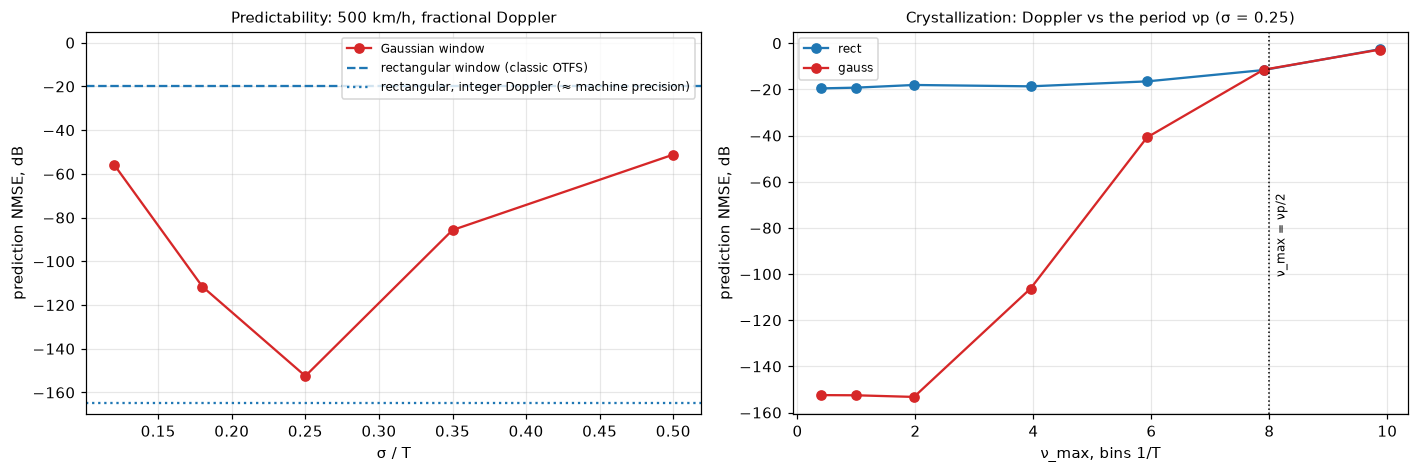

Prediction NMSE: rect, integer Doppler -299 dB; rect, fractional -19.6 dB; Gaussian σ = 0.25: -152.5 dB


In [6]:
def predict_nmse(kind, pth, Q, sigma=None):
    """NMSE of predicting H_eff from the response to one pilot (noise-free)"""
    H = eff_matrix(pth, kind, sigma)
    Yp = (H[:, kp * N + lp]).reshape(M, N)
    d, q, h = read_h(Yp, kp, lp, (-3, P_PATHS + 2), Q)
    Hp = predict_H(d, q, h)
    return np.sum(np.abs(Hp - H)**2) / np.sum(np.abs(H)**2)

sigmas = [0.12, 0.18, 0.25, 0.35, 0.5]
res = {"rect": [], "gauss": []}; res_i = []
for f in range(6):
    r = np.random.default_rng(200 + f)
    pf = draw_paths(r)
    res["rect"].append(predict_nmse("rect", pf, N // 2 - 1))
    res["gauss"].append([predict_nmse("gauss", pf, N // 2 - 1, sgm) for sgm in sigmas])
    res_i.append(predict_nmse("rect", draw_paths(np.random.default_rng(200 + f), integer=True), N // 2 - 1))
g = 10 * np.log10(np.mean(res["gauss"], 0))
speeds = np.array([100, 250, 500, 1000, 1500, 2000, 2500])
sp = {"rect": [], "gauss": []}
for v in speeds:
    nm = v / 3.6 * FC_GHZ * 1e9 / 3e8
    for kind in sp:
        sp[kind].append(np.mean([predict_nmse(kind, draw_paths(np.random.default_rng(300 + f), nu_max=nm), N // 2 - 1) for f in range(4)]))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
ax[0].plot(sigmas, g, "C3o-", label="Gaussian window")
ax[0].axhline(10 * np.log10(np.mean(res["rect"])), color="C0", ls="--", label="rectangular window (classic OTFS)")
ax[0].axhline(max(10 * np.log10(np.mean(res_i) + 1e-30), -165), color="C0", ls=":", label="rectangular, integer Doppler (≈ machine precision)")
ax[0].set_ylim(-170, 5); ax[0].set_xlabel("σ / T"); ax[0].set_ylabel("prediction NMSE, dB"); ax[0].legend(fontsize=8)
ax[0].set_title(f"Predictability: {SPEED_KMH} km/h, fractional Doppler", fontsize=10)
kmax = speeds / 3.6 * FC_GHZ * 1e9 / 3e8 * T
for kind, c in (("rect", "C0"), ("gauss", "C3")):
    ax[1].plot(kmax, 10 * np.log10(sp[kind]), c + "o-", label=kind)
ax[1].axvline(N / 2, color="k", ls=":", lw=1); ax[1].text(N / 2 + 0.1, -100, "ν_max = νp/2", rotation=90, fontsize=8)
ax[1].set_xlabel("ν_max, bins 1/T"); ax[1].set_ylabel("prediction NMSE, dB"); ax[1].legend(fontsize=8)
ax[1].set_title(f"Crystallization: Doppler vs the period νp (σ = {SIGMA})", fontsize=10)
plt.tight_layout(); plt.show()
print(f"Prediction NMSE: rect, integer Doppler {10*np.log10(np.mean(res_i)+1e-30):.0f} dB; rect, fractional {10*np.log10(np.mean(res['rect'])):.1f} dB; Gaussian σ = 0.25: {g[sigmas.index(0.25)]:.1f} dB")

## 5. Model-free channel estimation: BER
The same frame with a pilot and a guard band (23 % of the frame: the pilot read window plus the delays of data that would leak into it), with the guard energy given to the pilot. The receiver **does not look for paths**: it reads $h[d,q]$ over the whole window and builds $\hat H$ by twisted convolution. After the Gaussian RX window the DD noise is correlated, so it is whitened with $C^{-1/2}$ first and then LMMSE is applied.

- **Classic OTFS (rect)**: best of all with the true $H$, but with the estimate it hits a floor of ~$3\cdot10^{-3}$ — the unpredictability from section 4.
- **Zak-OTFS (Gaussian)**: ~3–5 dB worse than rect with the true $H$. This is the price of non-orthogonal Gaussian pulsones (section 1): neighbouring Doppler bins interfere, and LMMSE pays for it in noise. But the pilot-based estimate **has no floor**: beyond 25 dB there are no errors.

The filter choice is a trade-off between orthogonality (rect, sinc) and localization (Gaussian). Mohammed et al. use, for example, Gaussian-sinc and RRC pulses, which are localized almost like a Gaussian and orthogonal almost like a sinc.

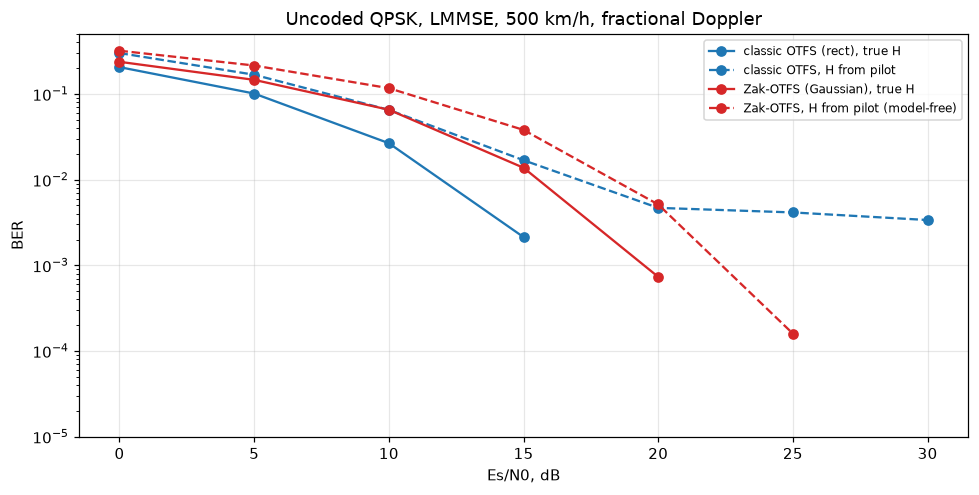

Guard: 23% of the frame, pilot +23.8 dB; the estimate uses every sample of the read window, with no threshold and no path model
rect : BER at 20 / 30 dB: true H 0.0e+00 / 0.0e+00, estimated 4.7e-03 / 3.4e-03
gauss: BER at 20 / 30 dB: true H 7.3e-04 / 0.0e+00, estimated 5.1e-03 / 0.0e+00


In [7]:
GUARD = np.zeros((M, N), bool)
GUARD[kp - (P_PATHS - 1) - 3:kp + P_PATHS + 3] = True         # pilot read window + delays of data that would leak into it; all Dopplers
DATA = ~GUARD.ravel(); XP = np.sqrt(GUARD.sum())
setups = ("rect", "gauss")
W = {k: noise_whitener(k) for k in setups}; Winv = {k: np.linalg.inv(W[k]) for k in setups}
snrs = np.arange(0, 31, 5)
ber = {f"{k}_{m}": np.zeros(len(snrs)) for k in setups for m in ("true", "est")}
for f in range(FRAMES):
    pth = draw_paths(rng)
    for kind in setups:
        H = W[kind] @ eff_matrix(pth, kind)
        b, xd = qpsk_bits(1, MN, rng); x = xd[0] * DATA; x[kp * N + lp] = XP
        for i, snr in enumerate(snrs):
            n0 = 10 ** (-snr / 10)
            yw = H @ x + np.sqrt(n0) * crandn(MN, rng)          # after whitening the noise is white
            d, q, h = read_h((Winv[kind] @ yw).reshape(M, N), kp, lp, (-3, P_PATHS + 2), N // 2 - 1)
            h = h / XP
            Hest = W[kind] @ predict_H(d, q, h)
            for Hd, tag in ((H, "true"), (Hest, "est")):
                z = lmmse(Hd[:, DATA], (yw - Hd[:, kp * N + lp] * XP)[None], n0)[0]
                ber[f"{kind}_{tag}"][i] += np.mean(hard_bits(z) != b[0, DATA])
ber = {k: v / FRAMES for k, v in ber.items()}
fig, a = plt.subplots(figsize=(9, 4.6))
for k, c, ls, lab in (("rect_true", "C0", "-", "classic OTFS (rect), true H"), ("rect_est", "C0", "--", "classic OTFS, H from pilot"),
                      ("gauss_true", "C3", "-", "Zak-OTFS (Gaussian), true H"), ("gauss_est", "C3", "--", "Zak-OTFS, H from pilot (model-free)")):
    ok = ber[k] > 0
    a.semilogy(snrs[ok], ber[k][ok], c + "o", ls=ls, label=lab)
a.set_ylim(1e-5, 0.5); a.set_xlabel("Es/N0, dB"); a.set_ylabel("BER"); a.legend(fontsize=8)
a.set_title(f"Uncoded QPSK, LMMSE, {SPEED_KMH} km/h, fractional Doppler")
plt.tight_layout(); plt.show()
print(f"Guard: {GUARD.mean():.0%} of the frame, pilot +{10*np.log10(XP**2):.1f} dB; the estimate uses every sample of the read window, with no threshold and no path model")
for kind in setups:
    print(f"{kind:5}: BER at 20 / 30 dB: true H {ber[kind+'_true'][4]:.1e} / {ber[kind+'_true'][6]:.1e}, estimated {ber[kind+'_est'][4]:.1e} / {ber[kind+'_est'][6]:.1e}")

## 6. Sensing: a target's Doppler from one pilot
The same pilot is a radar pulse: its DD response is the "radar image" $h_\text{eff}(\tau,\nu)$. Estimate the fractional Doppler of a single target from three samples around the peak:
- for the **Gaussian**, $\log|Y|$ is a parabola, and three-point interpolation is **exact**;
- for the **rectangle**, the peak is a Dirichlet kernel, and a parabola through $|Y|$ leaves a systematic bias that does not go away as SNR grows.

At 30 dB: rect ~150 Hz (16 % of a bin) — a bias floor; Gaussian ~20 Hz and still falling. This is Zak-OTFS's argument for ISAC (integrated sensing and communication): one waveform both carries data and measures delay and Doppler to better than a bin.

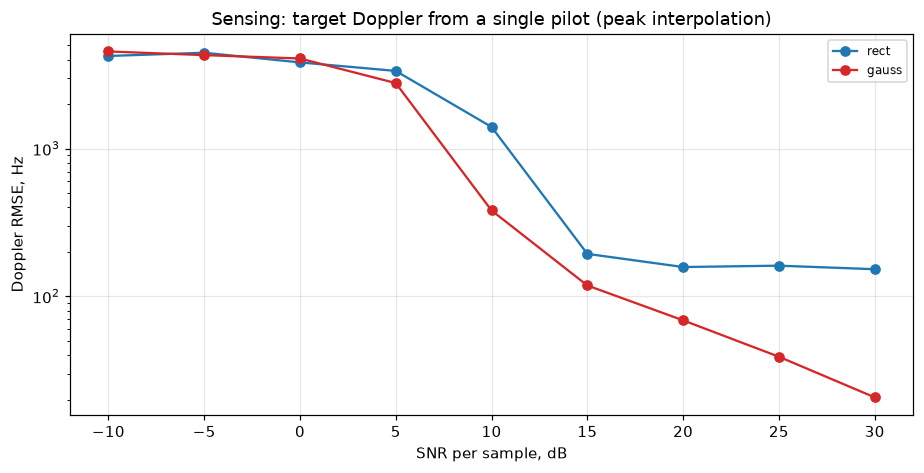

Doppler RMSE at 30 dB: rect 152.7 Hz (Dirichlet interpolation bias), Gaussian 20.71 Hz; bin 1/T = 938 Hz


In [8]:
def nu_estimate(Y, kind):
    """fractional Doppler from three samples around the peak: a parabola through log|Y| (exact for a Gaussian) or through |Y| (for rect)"""
    row = Y[kp]; i = np.argmax(np.abs(row))
    v = np.abs(row[[(i - 1) % N, i, (i + 1) % N]])
    v = np.log(v + 1e-30) if kind == "gauss" else v
    return i - lp + 0.5 * (v[0] - v[2]) / (v[0] - 2 * v[1] + v[2])
snrs6 = np.arange(-10, 31, 5); trials = 200
rm = {k: [] for k in ("rect", "gauss")}
for kind in rm:
    gt, gr = windows(kind)
    base = tx(Pp, gt)
    for snr in snrs6:
        err = []
        for t in range(trials):
            nu = rng.uniform(-K_MAX, K_MAX)
            r = channel(base, [(1.0, 0, nu / T)]) + np.sqrt(10 ** (-snr / 10)) * crandn(len(NABS), rng)
            err.append(nu_estimate(rx(r, gr), kind) - nu)
        rm[kind].append(np.sqrt(np.mean(np.square(err))))
fig, a = plt.subplots(figsize=(8.5, 4.4))
for kind, c in (("rect", "C0"), ("gauss", "C3")):
    a.semilogy(snrs6, np.array(rm[kind]) / T, c + "o-", label=kind)
a.set_xlabel("SNR per sample, dB"); a.set_ylabel("Doppler RMSE, Hz"); a.legend(fontsize=8)
a.set_title("Sensing: target Doppler from a single pilot (peak interpolation)")
plt.tight_layout(); plt.show()
print(f"Doppler RMSE at 30 dB: rect {rm['rect'][-1]/T:.1f} Hz (Dirichlet interpolation bias), Gaussian {rm['gauss'][-1]/T:.2f} Hz; bin 1/T = {1/T:.0f} Hz")

## Comparison: OFDM, OTFS 1.0, Zak-OTFS
| | OFDM | OTFS 1.0 (`otfs_sim`) | Zak-OTFS |
|---|---|---|---|
| Construction | IFFT over subcarriers | ISFFT + OFDM modulator | inverse Zak transform + a DD filter |
| Pulse | a rectangle per symbol | a rectangle per frame | any: sinc, Gaussian, RRC, Gaussian-sinc |
| Channel in its own domain | $H[m,n]$ varies everywhere | a 2-D convolution with modem-specific phases | a twisted convolution; the phase is a property of the DD plane |
| Fractional Doppler | ICI | Dirichlet tails, an estimation floor | a localized, predictable response |
| Channel estimation | pilots + interpolation | path search (a model) | read the pilot response (model-free) |
| Orthogonal symbols | yes | yes | not for the Gaussian (−3…5 dB with true H) |
| Sensing | separate reference signals | coarse (Dirichlet bias) | accurate, finer than a bin |
| Operating condition | $\nu_\max T\ll1$ | $\nu_\max<\nu_p/2$ | crystallization: $\tau_\max<\tau_p$, $2\nu_\max+\text{filter}<\nu_p$ |

Next in the series are **AFDM** and **OCDM**: they also separate delay and Doppler, but in a one-dimensional chirp frame, without a 2-D lattice.

## Things to try
- `SIGMA = 0.15` or `0.4` — in section 4 prediction gets worse on either side of the optimum, and in section 5 the cost of non-orthogonality changes
- `SPEED_KMH = 2000` — $\nu_\max\approx7.9$ bins, close to $\nu_p/2$: crystallization breaks and Zak-OTFS loses predictability, as on the right plot of section 4
- `DF = 30e3` (twice the $\nu_p$) at the same speed — crystallization comes back, but $\tau_p$ is half as long: a risk for long delays
- `P_PATHS = 2` — less diversity; the rect/Gaussian gap with true H changes
- in section 6 set `nu = 3.5` (exactly half a bin) for every trial — the rect bias is at its maximum